In [1]:
%load_ext autoreload
%autoreload 2

## IMPORTS
import os

import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
import seaborn as sns

import src.data_filepaths as data_filepaths
import src.utils.loaders as loaders
import src.utils.vis.colors_utils as colors_utils
from src.utils.df_tools import map_values_b_to_bp
from src.utils.loaders import process_loaded_building_df
from src.utils.vis.map import CategoricalColorMap, MapExplorer

# configs
sns.set_theme()

# Buildings Exploration

Headline statistics

* 237833 buildings total

In [2]:
## LOAD
# print(os.getcwd())

# here for testing
buildings = gpd.read_parquet(data_filepaths.OVERTURE_BUILDING)
b_gdf = buildings.to_crs("EPSG:3414")
b_gdf = b_gdf.set_index("id")

print(b_gdf.columns)
print(b_gdf.dtypes)
b_gdf.head()

# print(b_gdf["sources"].iloc[0][0])

Index(['names', 'sources', 'level', 'height', 'min_height', 'is_underground',
       'num_floors', 'num_floors_underground', 'min_floor', 'subtype', 'class',
       'facade_color', 'facade_material', 'roof_material', 'roof_shape',
       'roof_direction', 'roof_orientation', 'roof_color', 'roof_height',
       'geometry', 'has_parts', 'version', 'bbox', 'theme', 'type'],
      dtype='str')
names                       object
sources                     object
level                      float64
height                     float64
min_height                 float64
is_underground                bool
num_floors                 float64
num_floors_underground     float64
min_floor                  float64
subtype                        str
class                          str
facade_color                   str
facade_material                str
roof_material                  str
roof_shape                     str
roof_direction             float64
roof_orientation               str
roof_color  

,names,sources,level,height,min_height,is_underground,num_floors,num_floors_underground,min_floor,subtype,...,roof_direction,roof_orientation,roof_color,roof_height,geometry,has_parts,version,bbox,theme,type
id,,,,,,,,,,,,,,,,,,,,,
396eb35f-2fd0-4a23-bd73-c721c53ca662,None,"[{'property': '', 'dataset': 'OpenStreetMap', ...",NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,"POLYGON ((2736.591 22657.445, 2739.729 22652.4...",False,1,"{'xmin': 103.60630798339844, 'xmax': 103.60637...",buildings,building
db49e9d4-75d4-4c2c-8fd4-5e518014c335,None,"[{'property': '', 'dataset': 'OpenStreetMap', ...",NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,"POLYGON ((2964.986 22470.719, 2966.867 22467.6...",False,1,"{'xmin': 103.60836029052734, 'xmax': 103.60844...",buildings,building
8199239e-970c-4ef7-b6a5-58c55a617322,None,"[{'property': '', 'dataset': 'OpenStreetMap', ...",NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,"POLYGON ((2942.87 22446.781, 2945.385 22445.39...",False,1,"{'xmin': 103.60816192626953, 'xmax': 103.60822...",buildings,building
de9fee83-628e-4704-8681-0b2b1116e0a0,None,"[{'property': '', 'dataset': 'Google Open Buil...",NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,"POLYGON ((3348.278 22895.696, 3345.719 22901.0...",False,1,"{'xmin': 103.61177062988281, 'xmax': 103.61183...",buildings,building
dcd42c50-9fa6-4edf-ba7c-35a98dd45712,None,"[{'property': '', 'dataset': 'Google Open Buil...",NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,"POLYGON ((3351.016 22894.391, 3355.301 22897.1...",False,1,"{'xmin': 103.61181640625, 'xmax': 103.61188507...",buildings,building


In [3]:
# basic parameters
b_gdf["area"] = b_gdf.area
b_gdf["perimeter_m"] = b_gdf.length
b_gdf["centroid"] = b_gdf.centroid

b_gdf["src_dataset_label"] = b_gdf["sources"].map(
    lambda x: x[0]["dataset"]
)  # extract dataset label

print(b_gdf["height"].value_counts())
print(b_gdf["num_floors"].value_counts())
print(b_gdf["has_parts"].value_counts())
print(b_gdf["type"].value_counts())

# [] make histogram instead lmao

height
10.00     914
15.00     264
12.00     168
18.00      88
20.00      70
         ... 
207.00      1
33.15       1
19.70       1
15.50       1
4.30        1
Name: count, Length: 188, dtype: int64
num_floors
2.0     7587
3.0     4987
1.0     3466
4.0     2784
12.0    2023
5.0     1482
16.0    1244
13.0    1164
15.0     886
10.0     858
17.0     761
14.0     702
6.0      688
11.0     683
8.0      524
18.0     524
7.0      520
25.0     356
9.0      354
20.0     296
19.0     201
30.0     159
22.0     143
24.0     132
21.0     123
40.0      93
23.0      80
26.0      77
36.0      64
28.0      52
27.0      40
32.0      31
31.0      28
38.0      26
29.0      22
34.0      18
33.0      18
35.0      17
47.0      16
37.0      12
39.0      12
50.0      11
45.0      10
48.0       7
42.0       6
46.0       5
43.0       5
44.0       3
55.0       3
49.0       2
56.0       2
52.0       1
66.0       1
63.0       1
70.0       1
54.0       1
41.0       1
57.0       1
Name: count, dtype: int64
has_parts

In [4]:
print(b_gdf["subtype"].unique())
print(b_gdf["class"].unique())

<ArrowStringArray>
[             nan,     'industrial',     'commercial',    'residential',
    'outbuilding', 'transportation',          'civic',        'service',
      'education',  'entertainment',        'medical',      'religious',
       'military',   'agricultural']
Length: 14, dtype: str
<ArrowStringArray>
[                 nan,         'industrial',         'commercial',
          'warehouse',          'dormitory',               'roof',
             'office',            'parking',     'transportation',
        'residential',      'train_station',             'retail',
          'boathouse',             'garage',            'service',
        'manufacture',       'storage_tank',       'fire_station',
                'hut',               'shed',            'shelter',
         'university',         'grandstand',             'public',
         'apartments',              'house',            'college',
             'school',           'bungalow',             'church',
             

### Area

Max area at 99.9th percentile: 20405.16 m^2


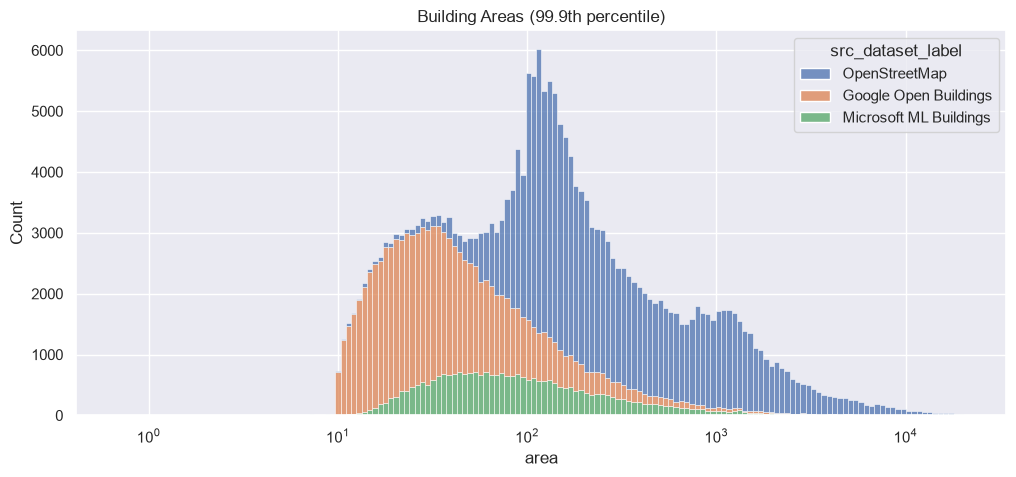

In [5]:
def plot_visualization_building_area():
    areas = b_gdf["area"]

    percentile_threshold = 99.9
    max_area = np.percentile(areas, percentile_threshold)
    print(f"Max area at {percentile_threshold}th percentile: {max_area:.2f} m^2")

    # PLOTTING
    fig, ax = plt.subplots(1, 1, figsize=(12, 5))

    ax.set_title(f"Building Areas ({percentile_threshold}th percentile)")

    sns.histplot(
        b_gdf[areas < max_area],
        x="area",
        ax=ax,
        hue="src_dataset_label",
        multiple="stack",
        log_scale=True,
    )


plot_visualization_building_area()

# Pre-Process: Building Removal

In [6]:
bp_gdf = process_loaded_building_df(gpd.read_parquet(data_filepaths.OVERTURE_BUILDING_PART))

## Zonal Removal

To remove:

* OSM
  * `landuse=construction`
  * `landuse=industrial_port`
* Masterplan

In [7]:
osm_landuse_gdf = loaders.load_osm_landuse_1_geojson_to_gdf(data_filepaths.OSM_landuse)
mp_landuse_gdf = loaders.load_masterplan_landuse_geojson_to_gdf(data_filepaths.MASTERPLAN_LANDUSE)

In [8]:
buildings_osm_merge = gpd.sjoin(
    b_gdf[["centroid"]].set_geometry("centroid"),
    osm_landuse_gdf,
    how="left",
    predicate="intersects",
)
# deduplicate
buildings_osm_merge = buildings_osm_merge[
    ~buildings_osm_merge.index.duplicated(keep="first")
]

buildings_osm_merge = buildings_osm_merge.drop(columns="index_right")

In [9]:
buildings_mp_merge = gpd.sjoin(
    b_gdf[["centroid"]].set_geometry("centroid"),
    mp_landuse_gdf,
    how="left",
    predicate="intersects",
)
# deduplicate
buildings_mp_merge = buildings_mp_merge[
    ~buildings_mp_merge.index.duplicated(keep="first")
]

buildings_mp_merge["landuse"].value_counts(dropna=False)

landuse
RESIDENTIAL                                  119051
BUSINESS 2                                    43988
RESERVE SITE                                   7472
COMMERCIAL                                     6080
SPECIAL USE                                    6059
EDUCATIONAL INSTITUTION                        5941
ROAD                                           5848
PORT / AIRPORT                                 4703
UTILITY                                        4195
PARK                                           4107
OPEN SPACE                                     3683
BUSINESS 1                                     3049
AGRICULTURE                                    2947
RESIDENTIAL WITH COMMERCIAL AT 1ST STOREY      2828
SPORTS & RECREATION                            2662
CIVIC & COMMUNITY INSTITUTION                  2599
COMMERCIAL & RESIDENTIAL                       2494
TRANSPORT FACILITIES                           1352
PLACE OF WORSHIP                               1306
WHIT

In [10]:
def visualize_mp_landuse_buildings():
    """
    Oh lord this is actually beautiful
    """
    temp_b_gdf = b_gdf.copy()
    temp_bp_gdf = bp_gdf.copy()

    temp_b_gdf[["mp_landuse", "mp_gpr", "mp_is_sdp"]] = buildings_mp_merge[["landuse", "gpr", "is_sdp"]]

    map_values_b_to_bp(temp_b_gdf, temp_bp_gdf, "mp_landuse", "mp_landuse")

    mp_lu_color_mapping = colors_utils.DEFAULT_MASTERPLAN_LANDUSE_COLORS

    cmap = CategoricalColorMap(
        cat_colors=list(mp_lu_color_mapping.values()),
        cat_labels=list(mp_lu_color_mapping.keys()),
        nan_color=np.array([0.2, 0.2, 0.2, 0.5]),
    )

    mapper = MapExplorer(
        temp_b_gdf,
        temp_bp_gdf,
        # enable_debug_mode=True,
    )
    return mapper.build_singleprop(
        "mp_landuse", cmap, title="Masterplan Landuse mapped onto Buildings"
    )


visualize_mp_landuse_buildings()

id
396eb35f-2fd0-4a23-bd73-c721c53ca662    6.0
db49e9d4-75d4-4c2c-8fd4-5e518014c335    6.0
8199239e-970c-4ef7-b6a5-58c55a617322    6.0
de9fee83-628e-4704-8681-0b2b1116e0a0    6.0
dcd42c50-9fa6-4edf-ba7c-35a98dd45712    6.0
Name: height_calc, dtype: float64


## Size/Source Removal

Per source:
* OSM
* Google
  * there are at least two aircraft (and way more that I noticed later on), at 250 and 285 m^2
* Microsoft

## Combine and Visualize

Previous

```plain
removal_reason
NaN                      108044
Size-Google               56826
Landuse-MP                41001
Size-Microsoft            19346
Landuse-OSM                4834
Size-OSM                   3552
Landuse-MP_coverage        1847
Buildingtype-Overture      1755
Bbox-removed-areas          628
Name: count, dtype: int64
```

New (with non-OSM residential zone bldgs rmved)

```plain
removal_reason
NaN                      107575
Size-Google               56826
Landuse-MP                41001
Size-Microsoft            19346
Landuse-OSM                4834
Size-OSM                   3552
Landuse-MP_coverage        1847
Buildingtype-Overture      1755
Bbox-removed-areas          628
Non-OSM_MP-res              469
Name: count, dtype: int64
```



In [11]:
from shapely import box


def full_removal_combine_and_vis(
    b_gdf: gpd.GeoDataFrame,
    bp_gdf: gpd.GeoDataFrame,
    buildings_osm_merge,  # [landuse]
    buildings_mp_merge,  # [landuse, gpr]
    mp_landuse_gdf,
    building_size_thresholds={
        "OSM": 60,  # this number is quite high, but for demand I think it's fine
        "Google": 400,
        "Microsoft": 400,
    },
    mp_zone_coverage_threshold=0.06,
):
    """
    Removes buildings from `b_gdf`/`bp_gdf` (mapped from `b_gdf`) and returns them with removal reasons added,
    but no removal done. Creates new columns `removal_reason`, `is_removed` for both `b_gdf` and `bp_gdf`.

    There are 9 removal reasons:
    * `Landuse-OSM`: This removes the OSM landuses:
        * `construction` - self explanatory
        * `landuse=industrial, industrial=port` - to complement the port Masterplan zonings, to achieve a more
        complete removal of those buildings. This is specifically for areas around Keppel Harbour, that have long
        been designated for future development, but as of writing in 2026 still houses active port facilities.
    * `Buildingtype-Overture` The following Overture building subtypes and classes are removed:
        * Subtypes: `transportation` (includes remaining transportation buildings, and crucially, `parking`),
            `outbuilding`.
        * Classes: `roof`, `pavilion`, `hut`, `shed`, `carport`, `bridge_structure`.
    * `Size-OSM`, `Size-Google`, `Size-Microsoft`: Buildings under a specified footprint size threshold are removed.
        The threshold will be higher for the ML-derived datasets from Google/Microsoft.
        This is specified in the parameter `building_size_thresholds`.
    * `Landuse-MP`: The following **non-demand** Masterplan zoning types are removed:
        `HEALTH & MEDICAL CARE`, `EDUCATIONAL INSTITUTION`, `PLACE OF WORSHIP`, `CIVIC & COMMUNITY INSTITUTION`,
        `PARK`, `BEACH AREA`, `SPORTS & RECREATION`, `WATERBODY`, `ROAD`, `TRANSPORT FACILITIES`,
        `MASS RAPID TRANSIT`, `LIGHT RAPID TRANSIT`, `UTILITY`, `CEMETERY`, `PORT / AIRPORT`, `SPECIAL USE`.
        * `RESERVE SITE` and `OPEN SPACE` are not removed and processed in a later step.
        * In the future, `UTILITY` should be processed as well, but that requires more specific conditions to
        exclude small-medium sized utility areas like substations, while retaining large utility facilities that have
        worker prescences.
    * `Landuse-MP_coverage`: Removes buildings in zones with less than the `mp_zone_coverage_threshold` parameter.
        Note that this uses the original set of buildings (i.e. unremoved buildings).
        Default threshold is set to 0.06, with 0.08 being a rough maximum before false positives start
        getting removed.
        * There is an exception for buildings in OSM `landuse=residential`. As certain areas containing bungalows
            (e.g. Mt Pleasant, Alexandria Pk) have so incredibly low density, they end up being false positives. This
            exception is in place for those buildings. If an area *is* tagged residential on OSM, that is likely
            correct and desirable anyway.
    * `Bbox-removed-areas`: These are custom defined areas where buildings are manually removed.
        They are typically areas slated for (or currently ongoing) future development,
        but currently have enough credible non-demand buildings in
        the zone to not be removed in earlier steps.
    * `Non-OSM_MP-res`: Non-OSM (i.e. ML-derived buildings) in residential plots. The vast majority of the time,
        these buildings are just construction or temporary buildings that have been picked up by these image
        recognition models, and OSM data is more than good enough on its own.
    """

    b_gdf = b_gdf.copy()
    bp_gdf = bp_gdf.copy()

    # clean removals that have no other condition
    MP_LANDUSES_TO_REMOVE = [
        "HEALTH & MEDICAL CARE",
        "EDUCATIONAL INSTITUTION",
        "PLACE OF WORSHIP",
        "CIVIC & COMMUNITY INSTITUTION",
        "PARK",
        "BEACH AREA",
        "SPORTS & RECREATION",
        "WATERBODY",
        "ROAD",
        "TRANSPORT FACILITIES",
        "MASS RAPID TRANSIT",
        "LIGHT RAPID TRANSIT",
        "UTILITY",
        "CEMETERY",
        "PORT / AIRPORT",
        "SPECIAL USE",
        # "RESERVE SITE",
        # "OPEN SPACE",
    ]
    MP_LANDUSE_REMOVAL_DICT = {
        landuse: "Landuse-MP" for landuse in MP_LANDUSES_TO_REMOVE
    }
    OVERTURE_REMOVAL_SUBTYPES = ["transportation", "outbuilding"]
    OVERTURE_REMOVAL_CLASSES = [
        "roof",
        "pavilion",
        "hut",
        "shed",
        "carport",
        "bridge_structure",
    ]

    b_gdf[["mp_landuse"]] = buildings_mp_merge[["landuse"]]
    b_gdf[["mp_gpr"]] = buildings_mp_merge[["gpr"]]
    b_gdf[["mp_OBJECTID"]] = buildings_mp_merge[["OBJECTID"]]

    # for removing buildings in areas with less than MP_COVERAGE_THRESHOLD occupancy
    # first calculate areas of a zone
    # this makes an assumption that building footprints are fully inside their zone
    # which is not true. but I can't be bothered
    b_mp_covered = b_gdf.groupby("mp_OBJECTID")["area"].sum()
    mp_area = mp_landuse_gdf.geometry.area

    b_mp_coverage_prop = b_gdf["mp_OBJECTID"].map(b_mp_covered / mp_area)

    # bounding box removal
    # specify in 4326, convert to 3414
    REMOVAL_BBOXES = {
        "southern_islands": gpd.GeoSeries(
            [box(103.69961, 1.24601, 103.81492, 1.18839)], crs=4326
        )
        .to_crs(b_gdf.crs)
        .iloc[0],
        "turf_city": gpd.GeoSeries(
            [box(103.794161, 1.332734, 103.797605, 1.335748)], crs=4326
        )
        .to_crs(b_gdf.crs)
        .iloc[0],
        "marina_south": gpd.GeoSeries(
            [box(103.859317, 1.267283, 103.872846, 1.281807)], crs=4326
        )
        .to_crs(b_gdf.crs)
        .iloc[0],
        "marina_bay_mrt": gpd.GeoSeries(
            [box(103.853470, 1.270952, 103.860240, 1.276465)], crs=4326
        )
        .to_crs(b_gdf.crs)
        .iloc[0],
    }

    ###################################

    REMOVE_REASONS_DICT = {
        "Landuse-OSM": (buildings_osm_merge["landuse"] == "construction")
        | (buildings_osm_merge["landuse"] == "industrial_port"),
        "Buildingtype-Overture": (b_gdf["subtype"].isin(OVERTURE_REMOVAL_SUBTYPES))
        | (b_gdf["class"].isin(OVERTURE_REMOVAL_CLASSES)),
        "Size-OSM": (b_gdf["src_dataset_label"] == "OpenStreetMap")
        & (b_gdf["area"] < building_size_thresholds["OSM"]),
        "Size-Google": (b_gdf["src_dataset_label"] == "Google Open Buildings")
        & (b_gdf["area"] < building_size_thresholds["Google"]),
        "Size-Microsoft": (b_gdf["src_dataset_label"] == "Microsoft ML Buildings")
        & (b_gdf["area"] < building_size_thresholds["Microsoft"]),
        "Landuse-MP": buildings_mp_merge[
            "landuse"
        ].isna(),  # remove NaNs here, about 130 of them
        "Landuse-MP_coverage": (b_mp_coverage_prop < mp_zone_coverage_threshold)
        & (
            buildings_osm_merge["landuse"] != "residential"
        ),  # prevent removal of very low-density bungalows
        "Bbox-removed-areas": b_gdf.geometry.within(REMOVAL_BBOXES["southern_islands"])
        | b_gdf.geometry.within(REMOVAL_BBOXES["turf_city"])
        | b_gdf.geometry.within(REMOVAL_BBOXES["marina_south"])
        | b_gdf.geometry.within(REMOVAL_BBOXES["marina_bay_mrt"]),
        "Non-OSM_MP-res": (buildings_mp_merge["landuse"] == "RESIDENTIAL")
        & (b_gdf["src_dataset_label"] != "OpenStreetMap"),
    }

    # now asasign all reasons at once
    b_gdf["removal_reason"] = np.select(
        list(REMOVE_REASONS_DICT.values()),
        list(REMOVE_REASONS_DICT.keys()),
        default=None,
    )

    # ALSO Remove LANDUSE-MP ones
    # apply without overwriting non-matches
    b_gdf["removal_reason"] = (
        buildings_mp_merge["landuse"]
        .map(MP_LANDUSE_REMOVAL_DICT)
        .fillna(b_gdf["removal_reason"])
    )

    map_values_b_to_bp(b_gdf, bp_gdf, "removal_reason", "removal_reason")

    # create boolean removed columns
    b_gdf["is_removed"] = ~b_gdf["removal_reason"].isna()
    bp_gdf["is_removed"] = ~bp_gdf["removal_reason"].isna()

    print(b_gdf["removal_reason"].value_counts(dropna=False))

    # sns.catplot(data=b_gdf, x="removal_reason", kind="count")

    title = (
        f"Removal thresholds: OSM {building_size_thresholds["OSM"]}"
        + f"; Google {building_size_thresholds["Google"]}"
        + f"; Microsoft {building_size_thresholds["Microsoft"]}"
    )

    # return

    mapper = MapExplorer(
        b_gdf,
        bp_gdf,
        # enable_debug_mode=True,
    )
    return mapper.build_configurable(["removal_reason"], title=title)


full_removal_combine_and_vis(
    b_gdf, bp_gdf, buildings_osm_merge, buildings_mp_merge, mp_landuse_gdf
)

removal_reason
NaN                      107286
Size-Google               56232
Landuse-MP                40524
Size-Microsoft            18925
Landuse-OSM                4461
Size-OSM                   3593
Landuse-MP_coverage        1878
Buildingtype-Overture      1788
Bbox-removed-areas          623
Non-OSM_MP-res              419
Name: count, dtype: int64
id
396eb35f-2fd0-4a23-bd73-c721c53ca662    6.0
db49e9d4-75d4-4c2c-8fd4-5e518014c335    6.0
8199239e-970c-4ef7-b6a5-58c55a617322    6.0
de9fee83-628e-4704-8681-0b2b1116e0a0    6.0
dcd42c50-9fa6-4edf-ba7c-35a98dd45712    6.0
Name: height_calc, dtype: float64


# Further Explorations